<a href="https://colab.research.google.com/github/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/Actividad2_12_DM_BenjaminAzocar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.12 DM

Benjamín Azócar

Seed:213410806

09.11.2026

**Dataset:** Breast Cancer Wisconsin (Diagnostic), Kaggle (`uciml/breast-cancer-wisconsin-data`)
**Objetivo:** entrenar un MLP que clasifique tumores (B = benigno, M = maligno) y registrar cada experimento en MLflow para comparar escalado, arquitectura, funcion de activacion y semilla.


In [1]:
!pip install -q mlflow pyngrok

In [2]:
import os, glob, random, time, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, mlflow
import sys, uuid
from sklearn.exceptions import ConvergenceWarning

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

SEED = 213410806
random.seed(SEED)
np.random.seed(SEED)

#Versiones
print("Python:      ", sys.version.split()[0])
print("pandas:      ", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("mlflow:      ", mlflow.__version__)
print("SEED:        ", SEED)

Python:       3.13.18
pandas:       2.2.3
scikit-learn: 1.6.1
mlflow:       3.18.0
SEED:         213410806


In [3]:
import kagglehub

path_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Contenido de la carpeta:", os.listdir(path_bc))

csvs = glob.glob(os.path.join(path_bc, "**", "*.csv"), recursive=True)
print("CSV encontrados:", [os.path.basename(c) for c in csvs])

columnas_requeridas = {"id", "diagnosis", "radius_mean", "area_mean", "smoothness_mean"}
candidatos = [c for c in csvs if columnas_requeridas.issubset(pd.read_csv(c, nrows=0).columns)]
if len(candidatos) != 1:
    raise ValueError(f"Se esperaba un CSV con el esquema de la actividad. Encontrados: {candidatos}")
df = pd.read_csv(candidatos[0])
print("CSV elegido:", os.path.basename(candidatos[0]))
print("\nDimensiones:", df.shape)
df.info()

100%|██████████| 48.6k/48.6k [00:00<00:00, 18.4MB/s]

Extracting files...
Contenido de la carpeta: ['data.csv']
CSV encontrados: ['data.csv']
CSV elegido: data.csv

Dimensiones: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  

In [4]:
nulos = df.isna().sum()
print("Columnas con nulos:")
print(nulos[nulos > 0])

# Columna completamente vacia (residuo del archivo) + identificador (no es una característica del tumor)
assert df.shape == (569, 33), f"Dimensiones inesperadas: {df.shape}"
assert "Unnamed: 32" in df.columns and df["Unnamed: 32"].isna().all()
df = df.drop(columns=["Unnamed: 32", "id"])

# Codificación de la etiqueta: M (maligno) = 1, B (benigno) = 0
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

assert not df.isna().any().any(), "Revisa las etiquetas o los valores faltantes."
print("\nDimensiones tras la limpieza:", df.shape)
balance = df["diagnosis"].value_counts()
pd.DataFrame({"cantidad": balance, "porcentaje": (balance / len(df) * 100).round(1)})

Columnas con nulos:
Unnamed: 32    569
dtype: int64

Dimensiones tras la limpieza: (569, 31)


,cantidad,porcentaje
diagnosis,,
0,357,62.7
1,212,37.3


####La columna Unnamed: 32 estaba completamente vacia (569 nulos), el tipico residuo basura de los archivos CSV. Así que la borre junto con la de id que al final es solo un identificador y no nos aporta nada sobre las caracteristicas del tumor.

####Para la columna diagnosis, pase los datos a numeros: M = 1 (maligno que es lo que más nos interesa detectar) y B = 0 (benigno).

####Balance de clases: hay 357 casos benignos (62,7%) y 212 malignos (37,3 %). Las clases están moderadamente desbalanceadas: hay casi el doble de benignos, pero la clase minoritaria sigue siendo grande. Por eso conviene mirar el recall de la clase maligna y no solo la exactitud.





In [5]:
cols_escala = ["radius_mean", "area_mean", "smoothness_mean"]
esc = df[cols_escala].agg(["min", "max"]).T
esc["rango"] = esc["max"] - esc["min"]
print(esc.round(4))

print(f"\nEl rango de area_mean es {esc.loc['area_mean', 'rango'] / esc.loc['smoothness_mean', 'rango']:,.0f} veces el de smoothness_mean")
print(f"El rango de area_mean es {esc.loc['area_mean', 'rango'] / esc.loc['radius_mean', 'rango']:,.0f} veces el de radius_mean")

                      min        max      rango
radius_mean        6.9810    28.1100    21.1290
area_mean        143.5000  2501.0000  2357.5000
smoothness_mean    0.0526     0.1634     0.1108

El rango de area_mean es 21,283 veces el de smoothness_mean
El rango de area_mean es 112 veces el de radius_mean


**Evidencia de escala:** area_mean va de 143,5 a 2501 (rango = 2.358), mientras que smoothness_mean va de 0,053 a 0,163 (rango = 0,11). El rango de area_mean es unas 21.000 veces el de smoothness_mean y unas 112 veces el de radius_mean. Si no se escalan, las variables de magnitud grande pueden influir más en las sumas ponderadas y dificultar la optimizacion.

Particion 80/20  con random_state=SEED, que mantengo fija en todo el todo momento asi cualquier diferencia entre ejecuciones se debe solo al cambio que se introduzco.

In [6]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({
    "completo": y.value_counts(normalize=True),
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)

Train: (455, 30) | Test: (114, 30)


,completo,train,test
diagnosis,,,
0,0.627,0.626,0.632
1,0.373,0.374,0.368


La estratificacion funciono: la proporcion de tumores malignos es practicamente la misma en el conjunto completo (0,373), en entrenamiento (0,374) y en prueba 0,368). El conjunto de prueba tiene 114 casos, 42 de ellos malignos.

In [7]:
import requests
from google.colab import userdata
from pyngrok import ngrok

tracking_uri = "http://127.0.0.1:5000"
token = userdata.get("NGROK_AUTHTOKEN")
env = dict(os.environ, MLFLOW_SERVER_ALLOWED_HOSTS="*",
           MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*")

# Si el proceso ya está activo, reutilízalo al volver a ejecutar esta celda.
if "servidor" not in globals() or servidor.poll() is not None:
    with open("mlflow_server.log", "w", encoding="utf-8") as log_servidor:
        servidor = subprocess.Popen(
            [sys.executable, "-m", "mlflow", "server",
             "--backend-store-uri", "sqlite:///mlflow.db",
             "--serve-artifacts", "--artifacts-destination", "./mlartifacts",
             "--host", "127.0.0.1", "--port", "5000"],
            env=env, stdout=log_servidor, stderr=subprocess.STDOUT,
        )

limite = time.monotonic() + 90
while time.monotonic() < limite:
    if servidor.poll() is not None:
        raise RuntimeError("MLflow terminó antes de arrancar. Revisa mlflow_server.log.")
    try:
        if requests.get(tracking_uri + "/health", timeout=2).ok:
            break
    except requests.RequestException:
        pass
    time.sleep(1)
else:
    servidor.terminate()
    raise TimeoutError("MLflow no respondió. Revisa mlflow_server.log antes de reintentar.")

ngrok.set_auth_token(token)
del token
ngrok.kill()
tunel = ngrok.connect(5000)
print("MLflow UI:", tunel.public_url)

MLflow UI: https://drank-turban-bottle.ngrok-free.dev


In [8]:
mlflow.set_tracking_uri(tracking_uri)

NOMBRE_EXP = "IEI097-L2.12-Azocar"
experimento = mlflow.set_experiment(NOMBRE_EXP)
LOTE = uuid.uuid4().hex[:8]
print("Lote:", LOTE)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento: ", NOMBRE_EXP)

2026/11/10 03:15:32 INFO mlflow.tracking.fluent: Experiment with name 'IEI097-L2.12-Azocar' does not exist. Creating a new experiment.


Lote: 1fe36c61
Tracking URI: http://127.0.0.1:5000
Experimento:  IEI097-L2.12-Azocar


**Hipotesis para los runs A y B antes de ejecutar**

Creo que el escalado mejorara el resultado. Las variables de este dataset tienen magnitudes muy distintas: el rango de area_mean es miles de veces el de smoothness_mean. En un MLP, cada neurona suma sus entradas multiplicadas por pesos que se ajustan con descenso del gradiente. Las variables de mayor magnitud pueden dominar esa suma y dificultar la optimización. En activaciones como tanh, entradas de magnitud elevada pueden provocar saturacion. Por eso espero que el run B con escalado tenga mayor exactitud y mayor sensibilidad que el run A sin escalar y que el run A tenga mas dificultades para ajustar incluso los datos de entrenamiento.

In [9]:
def correr_experimento(nombre, escalar, capas, activacion, semilla_modelo, fase,
                       alpha=1e-4, max_iter=500, lr_init=1e-3):
    """Entrena un MLP (con o sin escalado dentro de un Pipeline) y lo registra en MLflow."""
    pasos = []
    if escalar:
        # Dentro del Pipeline el escalador se ajusta SOLO con train: no hay fuga de datos
        pasos.append(("scaler", StandardScaler()))
    pasos.append(("mlp", MLPClassifier(hidden_layer_sizes=capas, activation=activacion,
                                       alpha=alpha, max_iter=max_iter,
                                       learning_rate_init=lr_init,
                                       random_state=semilla_modelo)))
    modelo = Pipeline(pasos)

    with mlflow.start_run(run_name=nombre):
        mlflow.set_tags({"fase": fase, "lote": LOTE, "python": sys.version.split()[0],
                         "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                         "mlflow": mlflow.__version__})
        mlflow.log_params({
            "escalado": escalar,
            "capas_ocultas": str(capas),
            "activacion": activacion,
            "alpha": alpha,
            "max_iter": max_iter,
            "learning_rate_init": lr_init,
            "random_state_modelo": semilla_modelo,
            "random_state_particion": SEED,
        })

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", ConvergenceWarning)
            modelo.fit(X_train, y_train)

        mlp = modelo.named_steps["mlp"]
        pred_tr = modelo.predict(X_train)
        pred_te = modelo.predict(X_test)

        fn = int(((y_test.to_numpy() == 1) & (pred_te == 0)).sum())
        fp = int(((y_test.to_numpy() == 0) & (pred_te == 1)).sum())
        metricas = {
            "acc_train": accuracy_score(y_train, pred_tr),
            "acc_test": accuracy_score(y_test, pred_te),
            "recall_maligno": recall_score(y_test, pred_te, pos_label=1),
            "f1_maligno": f1_score(y_test, pred_te, pos_label=1),
            "n_iter": mlp.n_iter_,
            "fn": fn,
            "fp": fp,
            "aviso_convergencia": int(any(issubclass(a.category, ConvergenceWarning) for a in avisos)),
        }
        mlflow.log_metrics(metricas)

        # Pérdida por época: permite comparar curvas de aprendizaje en la UI
        for epoca, perdida in enumerate(mlp.loss_curve_, start=1):
            mlflow.log_metric("train_loss", perdida, step=epoca)

        # Artefacto: matriz de confusión del conjunto de prueba
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ConfusionMatrixDisplay.from_predictions(
            y_test, pred_te, labels=[0, 1], display_labels=["Benigno", "Maligno"], ax=ax, colorbar=False)
        ax.set_title(nombre)
        mlflow.log_figure(fig, "matriz_confusion_test.png")
        plt.close(fig)

    return {"run": nombre, **metricas}

resultados = []
print("Función lista")

Función lista


In [10]:
resultados.append(correr_experimento("A_sin_escalar_30_relu", False, (30,), "relu", SEED, "experimentos"))
pd.DataFrame(resultados).set_index("run").round(4)

🏃 View run A_sin_escalar_30_relu at: http://127.0.0.1:5000/#/experiments/1/runs/c3a53cca98ee4264bfe19928e6f8c401
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,acc_train,acc_test,recall_maligno,f1_maligno,n_iter,fn,fp,aviso_convergencia
run,,,,,,,,
A_sin_escalar_30_relu,0.9341,0.9298,0.8571,0.9,305,6,2,0


Run A (sin escalar, 30 neuronas, ReLU). Obtuve una exactitud de 0.9341 en entrenamiento y 0.928 en prueba. La sensibilidad fue 0.8571 y el F1 0.9. De los 42 casos malignos de prueba 6 quedaron clasificados como benignos. Este run establece la referencia para comparar el efecto del escalado en B.

In [11]:
resultados.append(correr_experimento("B_escalado_30_relu", True, (30,), "relu", SEED, "experimentos"))
pd.DataFrame(resultados).set_index("run").round(4)

🏃 View run B_escalado_30_relu at: http://127.0.0.1:5000/#/experiments/1/runs/248fe78b6b1e4d6792dbebf2921b2daf
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,acc_train,acc_test,recall_maligno,f1_maligno,n_iter,fn,fp,aviso_convergencia
run,,,,,,,,
A_sin_escalar_30_relu,0.9341,0.9298,0.8571,0.900,305,6,2,0
B_escalado_30_relu,0.9956,0.9912,0.9762,0.988,456,1,0,0


**Run B (con escalado, 30 neuronas, ReLU).** Respecto de A, la exactitud de prueba paso de 0.9298 a 0.9912, la sensibilidad paso de 0.8571 a 0.9762 y los falsos negativos pasaron de 6 a 1. Estos resultados respaldan parcialmente mi hipótesis para esta partición.

In [12]:
resultados.append(correr_experimento("C_escalado_64-32_relu", True, (64, 32), "relu", SEED, "experimentos"))
pd.DataFrame(resultados).set_index("run").round(4)

🏃 View run C_escalado_64-32_relu at: http://127.0.0.1:5000/#/experiments/1/runs/250d9e7ca6634443929ef0f6e70d8d99
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,acc_train,acc_test,recall_maligno,f1_maligno,n_iter,fn,fp,aviso_convergencia
run,,,,,,,,
A_sin_escalar_30_relu,0.9341,0.9298,0.8571,0.9000,305,6,2,0
B_escalado_30_relu,0.9956,0.9912,0.9762,0.9880,456,1,0,0
C_escalado_64-32_relu,1.0000,0.9825,0.9524,0.9756,203,2,0,0


**Run C (con escalado, 64 y 32 neuronas, ReLU).** Comparado con B, la exactitud de entrenamiento cambio de 09956 a 1.0000, la exactitud de prueba cambio de 0.9912 a 0.9825 y la sensibilidad cambi de 0.9762 a 0.9524.


In [13]:
resultados.append(correr_experimento("D_escalado_64-32_tanh", True, (64, 32), "tanh", SEED, "experimentos"))
pd.DataFrame(resultados).set_index("run").round(4)

🏃 View run D_escalado_64-32_tanh at: http://127.0.0.1:5000/#/experiments/1/runs/ca3c5a1a2a9d4e70bef745082fbfb00a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,acc_train,acc_test,recall_maligno,f1_maligno,n_iter,fn,fp,aviso_convergencia
run,,,,,,,,
A_sin_escalar_30_relu,0.9341,0.9298,0.8571,0.9000,305,6,2,0
B_escalado_30_relu,0.9956,0.9912,0.9762,0.9880,456,1,0,0
C_escalado_64-32_relu,1.0000,0.9825,0.9524,0.9756,203,2,0,0
D_escalado_64-32_tanh,1.0000,0.9825,0.9762,0.9762,284,1,1,0


**Run D (con escalado, 64 y 32 neuronas, tanh).** Respecto de C, la exactitud de prueba se mantuvp, la sensibilidad de 0.9524 a 0.9762, los falsos negativos de 2 a 1 y los falsos positivos de 0 a 1.

In [14]:
# Variabilidad: configuracion C con 5 semillas del modelo (la particion se mantiene fija)
for s in range(SEED, SEED + 5):
    resultados.append(correr_experimento(f"C_semilla_{s}", True, (64, 32), "relu", s, "semillas"))

# Replicacion: la misma configuración C con mi seed original
resultados.append(correr_experimento(f"C_replica_seed{SEED}", True, (64, 32), "relu", SEED, "replica"))

tabla = pd.DataFrame(resultados).set_index("run")
tabla.round(4)

🏃 View run C_semilla_213410806 at: http://127.0.0.1:5000/#/experiments/1/runs/27ba606c136142d78af5cb21f5678d9b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run C_semilla_213410807 at: http://127.0.0.1:5000/#/experiments/1/runs/af13e4d514424969a07ccc7df2a811ee
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run C_semilla_213410808 at: http://127.0.0.1:5000/#/experiments/1/runs/5ac01f4c25184a3789c05a98ac25408c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run C_semilla_213410809 at: http://127.0.0.1:5000/#/experiments/1/runs/74cba2a4eea64919bb9b73614ce3d9af
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run C_semilla_213410810 at: http://127.0.0.1:5000/#/experiments/1/runs/20970b9870ae407bb7a20dcfc126c0ce
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run C_replica_seed213410806 at: http://127.0.0.1:5000/#/experiments/1/runs/46b035407380478b8679f2f2839e5716
🧪 View experiment at: http://1

,acc_train,acc_test,recall_maligno,f1_maligno,n_iter,fn,fp,aviso_convergencia
run,,,,,,,,
A_sin_escalar_30_relu,0.9341,0.9298,0.8571,0.9000,305,6,2,0
B_escalado_30_relu,0.9956,0.9912,0.9762,0.9880,456,1,0,0
C_escalado_64-32_relu,1.0000,0.9825,0.9524,0.9756,203,2,0,0
D_escalado_64-32_tanh,1.0000,0.9825,0.9762,0.9762,284,1,1,0
C_semilla_213410806,1.0000,0.9825,0.9524,0.9756,203,2,0,0
C_semilla_213410807,1.0000,0.9825,0.9524,0.9756,179,2,0,0
C_semilla_213410808,1.0000,0.9825,0.9524,0.9756,209,2,0,0
C_semilla_213410809,1.0000,0.9825,0.9524,0.9756,202,2,0,0
C_semilla_213410810,1.0000,0.9825,0.9524,0.9756,175,2,0,0


In [15]:
# Replicacion: run C vs. réplica (misma semilla -> mismas métricas)
cols_num = ["acc_train", "acc_test", "recall_maligno", "f1_maligno", "n_iter"]
c_run = tabla.loc["C_escalado_64-32_relu", cols_num]
rep = tabla.loc[f"C_replica_seed{SEED}", cols_num]
diferencia = float((c_run - rep).abs().max())
print("Diferencia absoluta máxima entre el run C y la réplica:", diferencia)
print("Igualdad exacta de métricas:", diferencia == 0)
print("Acuerdo con tolerancia absoluta de 1e-12:", diferencia <= 1e-12)

# Variacion con las 5 semillas
semillas = tabla[tabla.index.str.startswith("C_semilla_")]
resumen = pd.DataFrame({
    "mínimo": semillas[["acc_test", "recall_maligno"]].min(),
    "máximo": semillas[["acc_test", "recall_maligno"]].max(),
})
resumen["rango"] = resumen["máximo"] - resumen["mínimo"]
resumen["rango_pp"] = 100 * resumen["rango"]
print("Iteraciones con las cinco semillas:", semillas["n_iter"].tolist())
resumen.round(6)

Diferencia absoluta máxima entre el run C y la réplica: 0.0
Igualdad exacta de métricas: True
Acuerdo con tolerancia absoluta de 1e-12: True
Iteraciones con las cinco semillas: [203, 179, 209, 202, 175]


,mínimo,máximo,rango,rango_pp
acc_test,0.982456,0.982456,0.0,0.0
recall_maligno,0.952381,0.952381,0.0,0.0


**Replicacion.** El run C y la replica no tuvieron una diferencia absoluta maxima en las metricas comparadas, registro igualdad exacta.

**Variacion entre semillas.** En exactitud de prueba obtuve minimo 0.982456, maximo 0.982456 y rango 0. Las demas métricas permanecieron iguales entre estas cinco semillas.

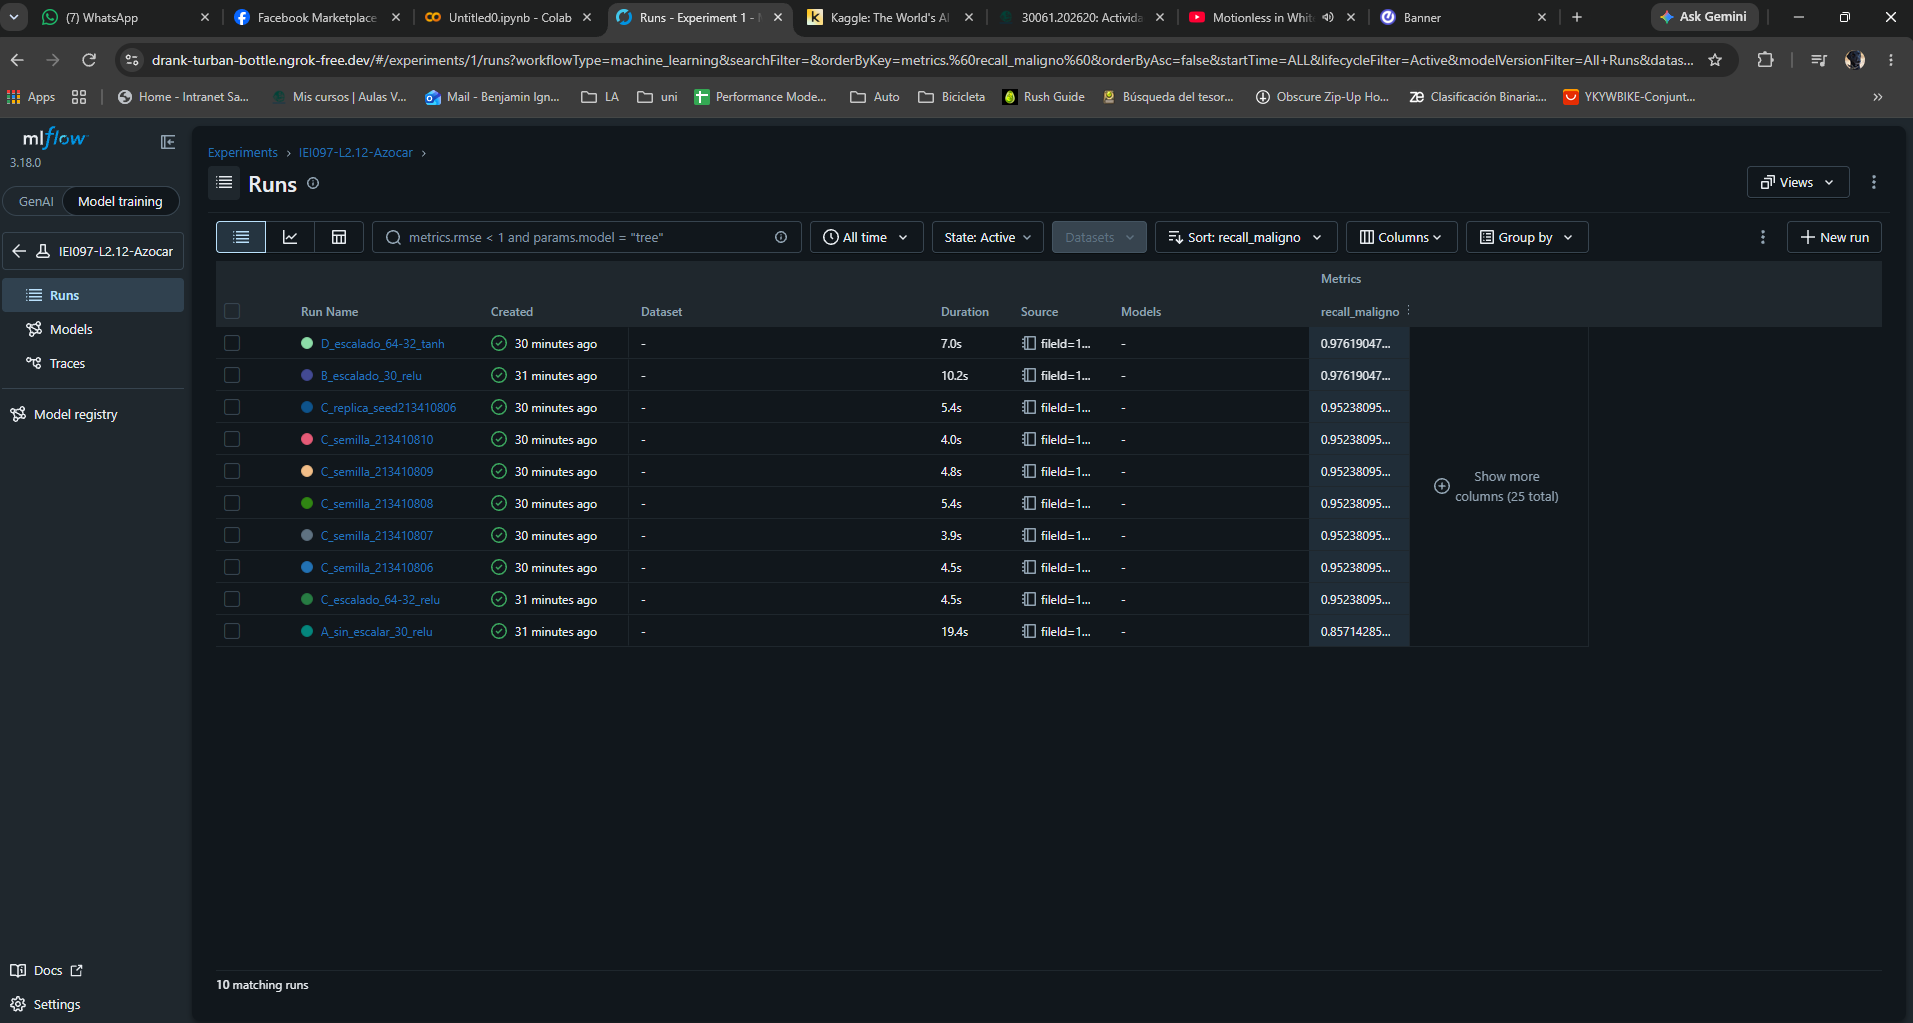 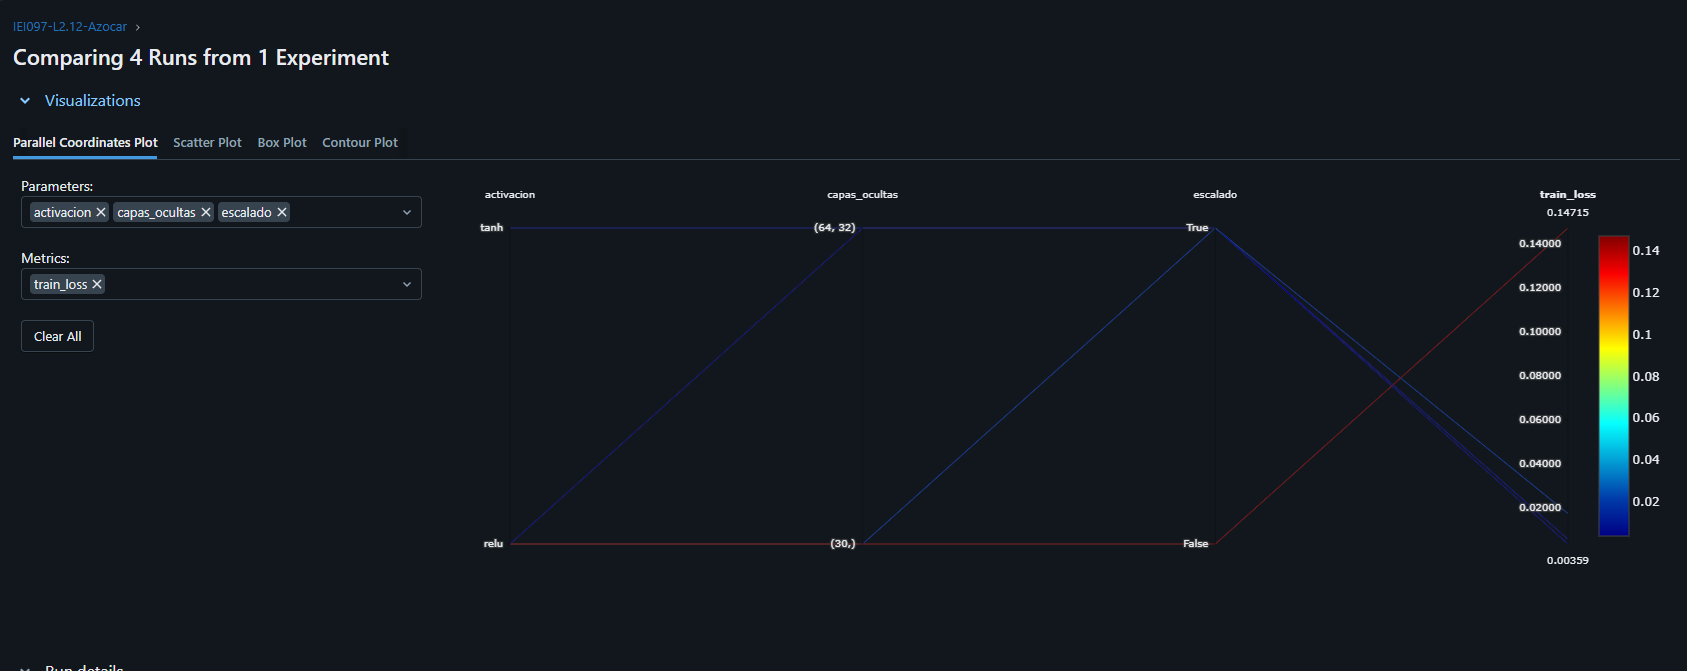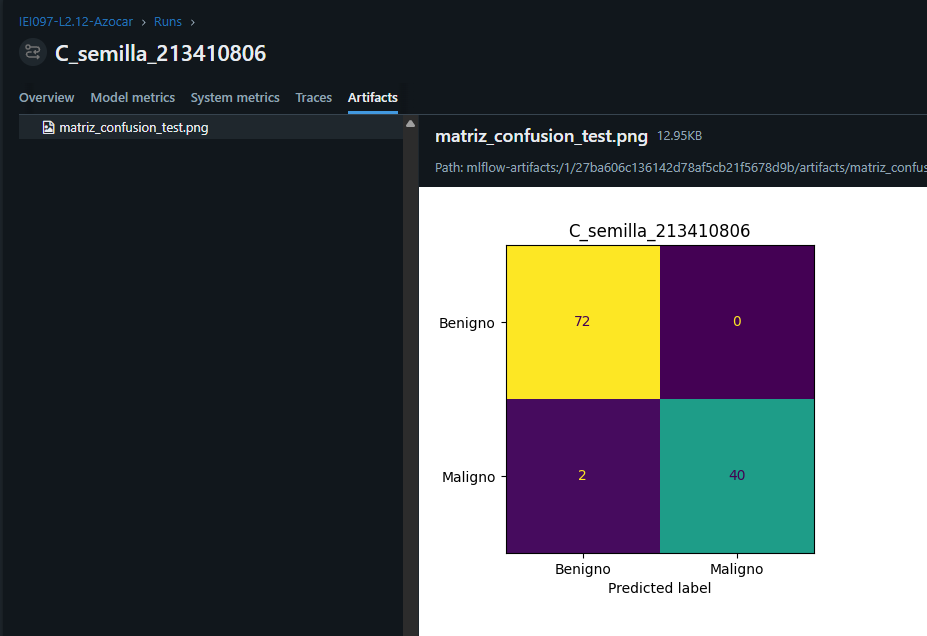

In [16]:
runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id],
    filter_string=f"tags.lote = '{LOTE}' AND attributes.status = 'FINISHED'",
    order_by=["metrics.recall_maligno DESC"],
)
nombres = runs["tags.mlflow.runName"] if "tags.mlflow.runName" in runs else pd.Series(dtype=str)
esperados = {"A_sin_escalar_30_relu", "B_escalado_30_relu",
             "C_escalado_64-32_relu", "D_escalado_64-32_tanh",
             f"C_replica_seed{SEED}"} | {f"C_semilla_{s}" for s in range(SEED, SEED + 5)}
faltantes = esperados - set(nombres)
if faltantes:
    raise ValueError(f"Faltan runs terminados en este lote: {sorted(faltantes)}")
print("Runs terminados de este lote:", len(runs))

cols = (["run_id", "tags.mlflow.runName", "tags.fase", "tags.lote", "status"]
        + [c for c in runs.columns if c.startswith("params.")]
        + [c for c in runs.columns if c.startswith("metrics.")])
runs_export = runs[cols]
runs_export.to_csv("runs.csv", index=False)

runs_export[["tags.mlflow.runName", "tags.fase", "metrics.acc_test", "metrics.recall_maligno", "metrics.f1_maligno"]].round(4)

Runs terminados de este lote: 10


,tags.mlflow.runName,tags.fase,metrics.acc_test,metrics.recall_maligno,metrics.f1_maligno
0,D_escalado_64-32_tanh,experimentos,0.9825,0.9762,0.9762
1,B_escalado_30_relu,experimentos,0.9912,0.9762,0.9880
2,C_replica_seed213410806,replica,0.9825,0.9524,0.9756
3,C_semilla_213410810,semillas,0.9825,0.9524,0.9756
4,C_semilla_213410809,semillas,0.9825,0.9524,0.9756
5,C_semilla_213410808,semillas,0.9825,0.9524,0.9756
6,C_semilla_213410807,semillas,0.9825,0.9524,0.9756
7,C_semilla_213410806,semillas,0.9825,0.9524,0.9756
8,C_escalado_64-32_relu,experimentos,0.9825,0.9524,0.9756
9,A_sin_escalar_30_relu,experimentos,0.9298,0.8571,0.9000


In [17]:
from google.colab import files
files.download("runs.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Preguntas de cierre

1. **Que cambio al escalar?** Al pasar de A_sin_escalar_30_relu a B_escalado_30_relu, la exactitud de prueba subio de 92,98 % a 99,12 % y la sensibilidad de la clase maligna paso de 85,71 % a 97,62 %. Los falsos negativos bajaron de 6 a 1. Como ambos runs usaron la misma arquitectura, activacion, semilla y partición, la diferencia observada respalda mi hipotesis sobre el escalado. La estandarizacion puso las variables en escalas comparables y se ajusto únicamente con los datos de entrenamiento dentro del pipeline.
2. **Mas capas y neuronas mejoraron el resultado?** En esta particion, el run C, con capas de 64 y 32 neuronas, obtuvo 98,25 % de exactitud y 95,24 % de sensibilidad en prueba. El run B, con una capa de 30 neuronas, obtuvo 99,12 % y 97,62 %, respectivamente. C acerto un caso menos y detecto un maligno menos. Aunque alcanzo el 100 % de exactitud en entrenamiento, eso por sí solo es insuficiente para afirmar que memorizo los datos.
3. **Cuanto variaron las metricas entre semillas?** Entre las configuraciones A–D, la exactitud de prueba vario de 92,98 % a 99,12 %, un rango de 6,14 puntos porcentuales. La sensibilidad vario de 85,71 % a 97,62 %, un rango de 11,91 puntos porcentuales con los valores redondeados de la tabla.
4. **Que error y metrica priorizaria?** En el contexto del ejercicio, priorizaria reducir los falsos negativos, porque representan casos malignos que el modelo clasifico como benignos y que podrian quedar sin una evaluacion posterior. Por eso miraria primero la sensibilidad de la clase maligna, junto con el número de falsos positivos. Por ejemplo, C y D lograron la misma exactitud (98,25 %), pero D detecto un maligno mas a cambio de clasificar un benigno adicional como maligno.
5. **Que aporta MLflow?** MLflow asocia a cada ejecución sus parametros, metricas, curva de perdida por época y matriz de confusion. Eso me permite filtrar y comparar los runs desde una misma interfaz.

In [18]:
ngrok.kill()
if servidor.poll() is None:
    servidor.terminate()
    servidor.wait(timeout=20)
print("Tunel cerrado y servidor detenido")


Túnel cerrado y servidor detenido
